# Comparison of Structural Materials Neutronic Performanca

In [1]:
import openmc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import structural_material_analysis as sma

/home/davide/anaconda3/envs/openmc0.15.1/lib/python3.13/site-packages/openmc/material.py:1512: UserWarning: Warning: sum of fractions do not add to 1, void fraction set to 0.09999999999999987
  warnings.warn(msg)


## General info

In [2]:
fusion_power = 525e6  # units Watts
energy_per_fusion_reaction = 17.6e6  # units eV
eV_to_Joules = 1.60218e-19  # multiplication factor to convert eV to Joules
number_of_neutrons_per_second = fusion_power / (energy_per_fusion_reaction * eV_to_Joules)
print('Number of neutrons per second', number_of_neutrons_per_second, '\n')

fw_volume = 2234489.71 # units cm^3
fw_surface = 4468977.87 # units cm^2
vessel_inner_volume = 3376578.27 # units cm^3
vessel_inner_surface = 4502100.88 # units cm^2
vessel_outer_volume = 6961366.51 # units cm^3
vessel_outer_surface = 4640897.08 # units cm^2

Number of neutrons per second 1.8618098749544654e+20 



In [3]:
inconel718 = sma.materials.inconel718
ss316l = sma.materials.ss316l
silicon_carbide = sma.materials.silicon_carbide
vcrti = sma.materials.vcrti
ods_eurofer = sma.materials.ods_eurofer
ht9 = sma.materials.ht9
rusfer = sma.materials.rusfer

In [4]:
sp_inconel718 = openmc.StatePoint(f"../1_neutronics/enr_flibe_results/inconel718.h5")
sp_ss316l = openmc.StatePoint(f"../1_neutronics/enr_flibe_results/ss316l.h5")
sp_silicon_carbide = openmc.StatePoint(f"../1_neutronics/enr_flibe_results/silicon_carbide.h5")
sp_vcrti = openmc.StatePoint(f"../1_neutronics/enr_flibe_results/vcrti.h5")
sp_ods_eurofer = openmc.StatePoint(f"../1_neutronics/enr_flibe_results/ods_eurofer.h5")
sp_ht9 = openmc.StatePoint(f"../1_neutronics/enr_flibe_results/ht9.h5")
sp_rusfer = openmc.StatePoint(f"../1_neutronics/enr_flibe_results/rusfer.h5")

## Neutronic analysis
### TBR

In [5]:
inconel718_tbr = sma.analysis.extract_tbr_contributions(sp_inconel718, "TBR")
ss316l_tbr = sma.analysis.extract_tbr_contributions(sp_ss316l, "TBR")
silicon_carbide_tbr = sma.analysis.extract_tbr_contributions(sp_silicon_carbide, "TBR")
vcrti_tbr = sma.analysis.extract_tbr_contributions(sp_vcrti, "TBR")
ods_eurofer_tbr = sma.analysis.extract_tbr_contributions(sp_ods_eurofer, "TBR")
ht9_tbr = sma.analysis.extract_tbr_contributions(sp_ht9, "TBR")
rusfer_tbr = sma.analysis.extract_tbr_contributions(sp_rusfer, "TBR")

             TBR Total  TBR Channel (Li6)  TBR Channel (Li7)  \
Material                                                       
Inconel 718    1.10736            0.28513            0.00159   
RUSFER         1.15126            0.27810            0.00165   
HT9            1.21299            0.29230            0.00160   
ODS-EUROFER    1.21368            0.28898            0.00160   
SiC/SiC        1.10212            0.24211            0.00184   
V-4Cr-4Ti      1.25885            0.31594            0.00169   

             TBR Blanket (Li6)  TBR Blanket (Li7)  
Material                                           
Inconel 718            0.81493            0.00571  
RUSFER                 0.86522            0.00630  
HT9                    0.91333            0.00577  
ODS-EUROFER            0.91725            0.00585  
SiC/SiC                0.85076            0.00740  
V-4Cr-4Ti              0.93461            0.00661  


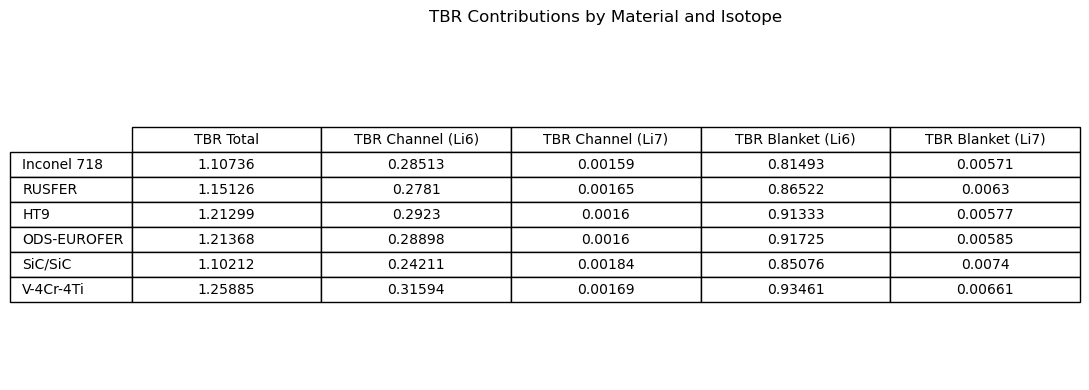

In [6]:
materials = {
    "Inconel 718": sp_inconel718,
    # "SS316L": sp_ss316l,
    "RUSFER": sp_rusfer,
    "HT9": sp_ht9,
    "ODS-EUROFER": sp_ods_eurofer,
    "SiC/SiC": sp_silicon_carbide,
    "V-4Cr-4Ti": sp_vcrti,
}

rows = []

for name, sp in materials.items():
    tbr_total = sma.analysis.extract_tbr_contributions(sp, "TBR")
    tbr_cc     = sma.analysis.extract_tbr_contributions(sp, "TBR channel")
    tbr_blanket = sma.analysis.extract_tbr_contributions(sp, "TBR blanket")
    
    rows.append([
        name,
        tbr_total["TBR"],
        tbr_cc["Li6"], tbr_cc["Li7"],
        tbr_blanket["Li6"], tbr_blanket["Li7"]
    ])

df = pd.DataFrame(rows, columns=[
    "Material",
    "TBR Total",
    "TBR Channel (Li6)", "TBR Channel (Li7)",
    "TBR Blanket (Li6)", "TBR Blanket (Li7)"
])
df.set_index("Material", inplace=True)

print(df.round(5))

fig, ax = plt.subplots(figsize=(11, 4))
ax.axis('off')
table = ax.table(cellText=df.round(5).values,
                 colLabels=df.columns,
                 rowLabels=df.index,
                 loc='center',
                 cellLoc='center',
                 colLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.4)

plt.title("TBR Contributions by Material and Isotope", fontsize=12, pad=20)
plt.tight_layout()
plt.savefig("tbr_contributions_by_isotope.pdf", bbox_inches="tight")
plt.show()


In [7]:
0.2923 + 0.0016+ 0.9133 + 0.0058

1.213

### Neutron Spectra

Mean neutron flux in Inconel 718: 6.58e+14 ± 4.89e+12 n/cm²-s
Mean neutron flux in RUSFER: 6.52e+14 ± 5.07e+12 n/cm²-s
Mean neutron flux in HT9: 7.00e+14 ± 5.50e+12 n/cm²-s
Mean neutron flux in ODS-EUROFER: 6.99e+14 ± 5.49e+12 n/cm²-s
Mean neutron flux in SiC/SiC: 5.97e+14 ± 5.11e+12 n/cm²-s
Mean neutron flux in V-4Cr-4Ti: 6.95e+14 ± 5.22e+12 n/cm²-s


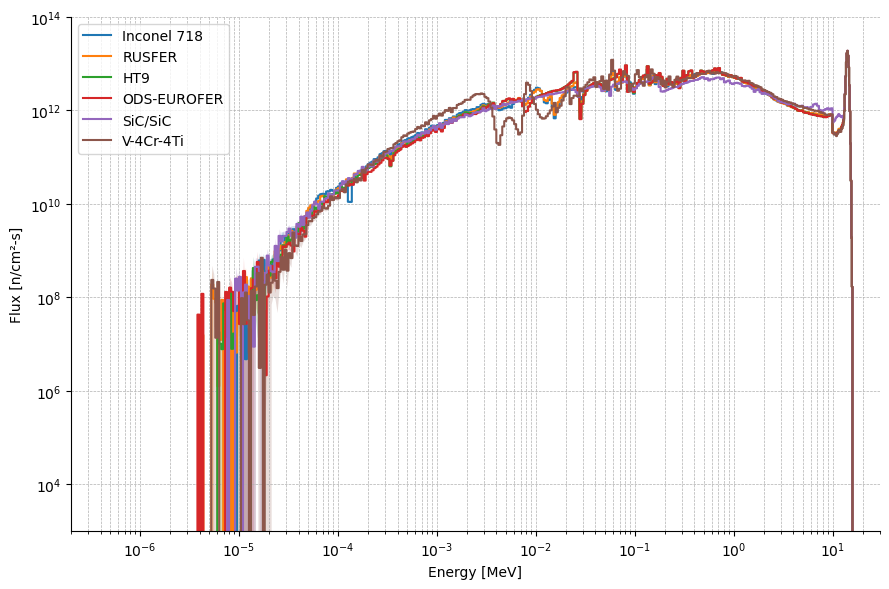

In [8]:
inconel718_ns_str1 = sp_inconel718.get_tally(name="neutron_spectra_str1")
ss316l_ns_str1 = sp_ss316l.get_tally(name="neutron_spectra_str1")
silicon_carbide_ns_str1 = sp_silicon_carbide.get_tally(name="neutron_spectra_str1")
vcrti_ns_str1 = sp_vcrti.get_tally(name="neutron_spectra_str1")
ods_eurofer_ns_str1 = sp_ods_eurofer.get_tally(name="neutron_spectra_str1")
ht9_ns_str1 = sp_ht9.get_tally(name="neutron_spectra_str1")
rusfer_ns_str1 = sp_rusfer.get_tally(name="neutron_spectra_str1")

sma.analysis.plot_multiple_neutron_spectra(
    tally_list=[inconel718_ns_str1, rusfer_ns_str1, ht9_ns_str1, ods_eurofer_ns_str1, silicon_carbide_ns_str1, vcrti_ns_str1],
    region_names=["Inconel 718", "RUSFER", "HT9", "ODS-EUROFER","SiC/SiC", "V-4Cr-4Ti"],
    region_volumes_cm3=[vessel_inner_volume, vessel_inner_volume, vessel_inner_volume, vessel_inner_volume, vessel_inner_volume, vessel_inner_volume],
    number_of_neutrons_per_second=number_of_neutrons_per_second  
)

### EM

In [9]:
E_source = 14.1
em_tally = sp_inconel718.get_tally(name='heating_full')
inconel718_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_ss316l.get_tally(name='heating_full')
ss316l_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_silicon_carbide.get_tally(name='heating_full')
silicon_carbide_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_vcrti.get_tally(name='heating_full')
vcrti_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_ods_eurofer.get_tally(name='heating_full')
ods_eurofer_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_ht9.get_tally(name='heating_full')
ht9_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_rusfer.get_tally(name='heating_full')
rusfer_em = em_tally.mean.sum() / 1e6 / E_source

em_values = {
    "Inconel 718": inconel718_em,
    "RUSFER": rusfer_em,
    "HT9": ht9_em,
    "ODS-EUROFER": ods_eurofer_em,
    # "SS316L": ss316l_em,
    "SiC/SiC": silicon_carbide_em,
    "V-4Cr-4Ti": vcrti_em
}

# Creazione DataFrame
df_em = pd.DataFrame(list(em_values.items()), columns=["Material", "EM Factor"])
df_em = df_em.set_index("Material")
df_em["EM Factor"] = df_em["EM Factor"].map(lambda x: f"{x:.4f}")

df_em

,EM Factor
Material,
Inconel 718,1.1463
RUSFER,1.1471
HT9,1.1637
ODS-EUROFER,1.1638
SiC/SiC,1.1264
V-4Cr-4Ti,1.1632


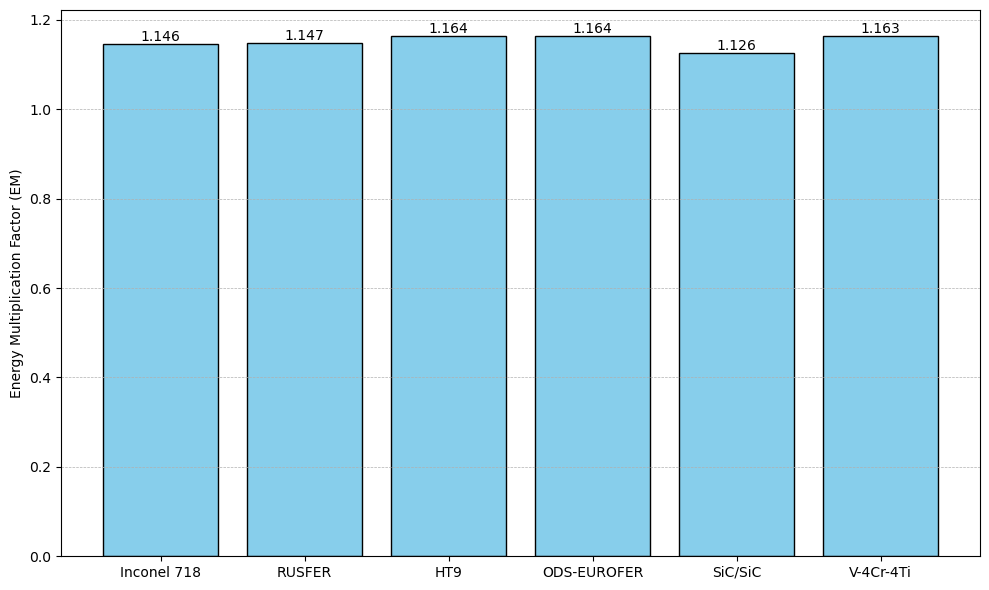

In [10]:
# Prepare data
materials = list(em_values.keys())
values = list(em_values.values())

# Plotting
plt.figure(figsize=(10, 6))
bars = plt.bar(materials, values, color='skyblue', edgecolor='black')

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height, f"{height:.3f}", ha='center', va='bottom', fontsize=10)

# Aesthetics
plt.ylabel("Energy Multiplication Factor (EM)")
plt.grid(axis='y', linestyle='--', linewidth=0.5)
plt.tight_layout()

plt.show()


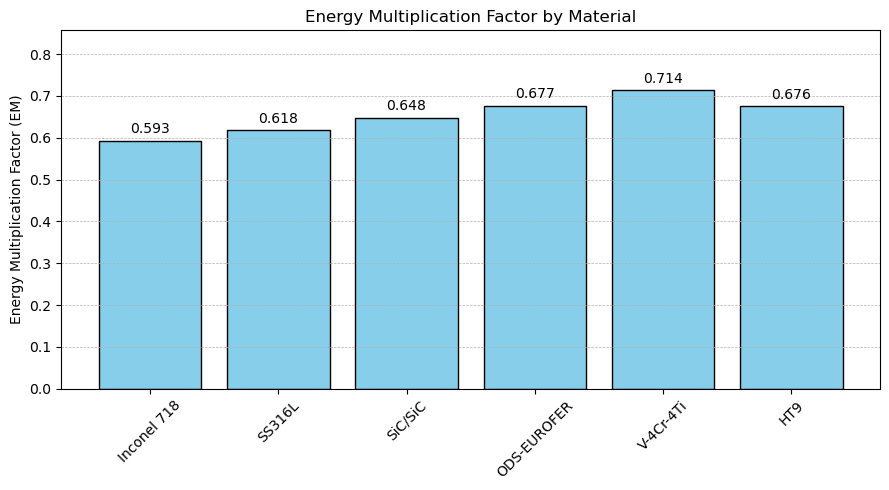

In [11]:
import matplotlib.pyplot as plt

# Material names and corresponding EM values
materials = ["Inconel 718", "SS316L", "SiC/SiC", "ODS-EUROFER", "V-4Cr-4Ti", "HT9"]
em_values = [0.593, 0.618, 0.648, 0.677, 0.714, 0.676]

# Create bar chart
plt.figure(figsize=(9, 5))
bars = plt.bar(materials, em_values, color='skyblue', edgecolor='black')

# Add value labels above bars
for bar, value in zip(bars, em_values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f'{value:.3f}', ha='center', va='bottom', fontsize=10)

# Customize axes and title
plt.ylabel("Energy Multiplication Factor (EM)")
plt.title("Energy Multiplication Factor by Material")
plt.ylim(0, max(em_values) * 1.2)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', linewidth=0.5)
plt.tight_layout()

plt.show()


### DPA

In [12]:
dpa_tally_str1 = sp_inconel718.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['inconel718']
inconel718_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,  
    atomic_mass_u=props["mass_u"],                
    density_g_per_cm3=inconel718.density,  
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],  
)

dpa_tally_str1 = sp_ss316l.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['ss316l']
ss316l_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=ss316l.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

dpa_tally_str1 = sp_silicon_carbide.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['silicon_carbide']
silicon_carbide_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=silicon_carbide.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

dpa_tally_str1 = sp_vcrti.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['vcrti']
vcrti_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=vcrti.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

dpa_tally_str1 = sp_ods_eurofer.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['ods_eurofer']
ods_eurofer_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=ods_eurofer.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

dpa_tally_str1 = sp_ht9.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['ht9']
ht9_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=ht9.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

dpa_tally_str1 = sp_rusfer.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['rusfer']
rusfer_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=rusfer.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

dpa_values = {
    "Inconel 718": inconel718_dpa['DPA'].item(),
    "RUSFER": rusfer_dpa['DPA'].item(),
    "HT9": ht9_dpa['DPA'].item(),
    "ODS-EUROFER": ods_eurofer_dpa['DPA'].item(),
    # "SS316L": ss316l_dpa['DPA'].item(),
    "SiC/SiC": silicon_carbide_dpa['DPA'].item(),
    "V-4Cr-4Ti": vcrti_dpa['DPA'].item(),
}

# Creazione DataFrame
df_dpa = pd.DataFrame(list(dpa_values.items()), columns=["Material", "DPA"])
df_dpa = df_dpa.set_index("Material")
df_dpa["DPA"] = df_dpa["DPA"].map(lambda x: f"{x:.4f}")

df_dpa

,DPA
Material,
Inconel 718,14.0887
RUSFER,11.9901
HT9,12.5135
ODS-EUROFER,12.6812
SiC/SiC,16.6351
V-4Cr-4Ti,15.0236


### Absorption rate

In [13]:
tally_abs = sp_inconel718.get_tally(name="absorption_str1")
inconel718_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_ss316l.get_tally(name="absorption_str1")
ss316l_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_silicon_carbide.get_tally(name="absorption_str1")
silicon_carbide_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_vcrti.get_tally(name="absorption_str1")
vcrti_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_ods_eurofer.get_tally(name="absorption_str1")
ods_eurofer_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_ht9.get_tally(name="absorption_str1")
ht9_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_rusfer.get_tally(name="absorption_str1")
rusfer_abs = tally_abs.get_pandas_dataframe()


abs_values = {
    "Inconel 718": inconel718_abs['mean'].item(),
    "RUSFER": rusfer_abs['mean'].item(),
    "HT9": ht9_abs['mean'].item(),
    "ODS-EUROFER": ods_eurofer_abs['mean'].item(),
    #"SS316L": ss316l_abs['mean'].item(),
    "SiC/SiC": silicon_carbide_abs['mean'].item(),
    "V-4Cr-4Ti": vcrti_abs['mean'].item(),
}

# Creazione DataFrame
df_abs = pd.DataFrame(list(abs_values.items()), columns=["Material", "Absorption"])
df_abs = df_abs.set_index("Material")
df_abs["Absorption"] = df_abs["Absorption"].map(lambda x: f"{x:.4f}")

df_abs

,Absorption
Material,
Inconel 718,0.0660
RUSFER,0.0450
HT9,0.0275
ODS-EUROFER,0.0282
SiC/SiC,0.0490
V-4Cr-4Ti,0.0193


### Power density

In [14]:
inconel718_pd_df = sma.analysis.compute_region_heating(sp_inconel718, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
ss316l_pd_df = sma.analysis.compute_region_heating(sp_ss316l, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
silicon_carbide_pd_df = sma.analysis.compute_region_heating(sp_silicon_carbide, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
vcrti_pd_df = sma.analysis.compute_region_heating(sp_vcrti, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
ods_eurofer_pd_df = sma.analysis.compute_region_heating(sp_ods_eurofer, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
ht9_pd_df = sma.analysis.compute_region_heating(sp_ht9, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
rusfer_pd_df = sma.analysis.compute_region_heating(sp_rusfer, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)

In [15]:
inconel718_pd = inconel718_pd_df.loc[inconel718_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
ss316l_pd = ss316l_pd_df.loc[ss316l_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
silicon_carbide_pd = silicon_carbide_pd_df.loc[silicon_carbide_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
vcrti_pd = vcrti_pd_df.loc[vcrti_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
ods_eurofer_pd = ods_eurofer_pd_df.loc[ods_eurofer_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
ht9_pd = ht9_pd_df.loc[ht9_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
rusfer_pd = rusfer_pd_df.loc[rusfer_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]

pd_values = {
    "Inconel 718": inconel718_pd,
    # "SS316L": ss316l_pd,
    "RUSFER": rusfer_pd,
    "HT9": ht9_pd,
    "ODS-EUROFER": ods_eurofer_pd,
    "SiC/SiC": silicon_carbide_pd,
    "V-4Cr-4Ti": vcrti_pd,
}

# Creazione DataFrame
df_pd = pd.DataFrame(list(pd_values.items()), columns=["Material", "Power Density [MW/m³]"])
df_pd = df_pd.set_index("Material")
df_pd["Power Density [MW/m³]"] = df_pd["Power Density [MW/m³]"].map(lambda x: f"{x:.4f}")

df_pd

,Power Density [MW/m³]
Material,
Inconel 718,12.8902
RUSFER,10.6803
HT9,10.7842
ODS-EUROFER,10.7347
SiC/SiC,8.7648
V-4Cr-4Ti,7.5756


### H & He production

In [16]:
sp_inconel718 = openmc.StatePoint(f"../1_neutronics/results/inconel718.h5")
sp_silicon_carbide = openmc.StatePoint(f"../1_neutronics/results/silicon_carbide.h5")
sp_vcrti = openmc.StatePoint(f"../1_neutronics/results/vcrti.h5")
sp_ods_eurofer = openmc.StatePoint(f"../1_neutronics/results/ods_eurofer.h5")
sp_ht9 = openmc.StatePoint(f"../1_neutronics/results/ht9.h5")
sp_rusfer = openmc.StatePoint(f"../1_neutronics/results/rusfer.h5")

In [17]:
h1_tally_str1 = sp_inconel718.get_tally(name="H1-production_str1")
df_h1_str1 = h1_tally_str1.get_pandas_dataframe()
h2_tally_str1 = sp_inconel718.get_tally(name="H2-production_str1")
df_h2_str1 = h2_tally_str1.get_pandas_dataframe()
h3_tally_str1 = sp_inconel718.get_tally(name="H3-production_str1")
df_h3_str1 = h3_tally_str1.get_pandas_dataframe()
he3_tally_str1 = sp_inconel718.get_tally(name="He3-production_str1")
df_he3_str1 = he3_tally_str1.get_pandas_dataframe()
he4_tally_str1 = sp_inconel718.get_tally(name="He4-production_str1")
df_he4_str1 = he4_tally_str1.get_pandas_dataframe()

h_inconel718 = df_h1_str1['mean'].mean() + df_h2_str1['mean'].mean() + df_h3_str1['mean'].mean()
he_inconel718 = df_he3_str1['mean'].mean() + df_he4_str1['mean'].mean()

h1_tally_str1 = sp_rusfer.get_tally(name="H1-production_str1")
df_h1_str1 = h1_tally_str1.get_pandas_dataframe()
h2_tally_str1 = sp_rusfer.get_tally(name="H2-production_str1")
df_h2_str1 = h2_tally_str1.get_pandas_dataframe()
h3_tally_str1 = sp_rusfer.get_tally(name="H3-production_str1")
df_h3_str1 = h3_tally_str1.get_pandas_dataframe()
he3_tally_str1 = sp_rusfer.get_tally(name="He3-production_str1")
df_he3_str1 = he3_tally_str1.get_pandas_dataframe()
he4_tally_str1 = sp_rusfer.get_tally(name="He4-production_str1")
df_he4_str1 = he4_tally_str1.get_pandas_dataframe()

h_rusfer = df_h1_str1['mean'].mean() + df_h2_str1['mean'].mean() + df_h3_str1['mean'].mean()
he_rusfer = df_he3_str1['mean'].mean() + df_he4_str1['mean'].mean()

h1_tally_str1 = sp_ht9.get_tally(name="H1-production_str1")
df_h1_str1 = h1_tally_str1.get_pandas_dataframe()
h2_tally_str1 = sp_ht9.get_tally(name="H2-production_str1")
df_h2_str1 = h2_tally_str1.get_pandas_dataframe()
h3_tally_str1 = sp_ht9.get_tally(name="H3-production_str1")
df_h3_str1 = h3_tally_str1.get_pandas_dataframe()
he3_tally_str1 = sp_ht9.get_tally(name="He3-production_str1")
df_he3_str1 = he3_tally_str1.get_pandas_dataframe()
he4_tally_str1 = sp_ht9.get_tally(name="He4-production_str1")
df_he4_str1 = he4_tally_str1.get_pandas_dataframe()

h_ht9 = df_h1_str1['mean'].mean() + df_h2_str1['mean'].mean() + df_h3_str1['mean'].mean()
he_ht9 = df_he3_str1['mean'].mean() + df_he4_str1['mean'].mean()

h1_tally_str1 = sp_ods_eurofer.get_tally(name="H1-production_str1")
df_h1_str1 = h1_tally_str1.get_pandas_dataframe()
h2_tally_str1 = sp_ods_eurofer.get_tally(name="H2-production_str1")
df_h2_str1 = h2_tally_str1.get_pandas_dataframe()
h3_tally_str1 = sp_ods_eurofer.get_tally(name="H3-production_str1")
df_h3_str1 = h3_tally_str1.get_pandas_dataframe()
he3_tally_str1 = sp_ods_eurofer.get_tally(name="He3-production_str1")
df_he3_str1 = he3_tally_str1.get_pandas_dataframe()
he4_tally_str1 = sp_ods_eurofer.get_tally(name="He4-production_str1")
df_he4_str1 = he4_tally_str1.get_pandas_dataframe()

h_ods_eurofer = df_h1_str1['mean'].mean() + df_h2_str1['mean'].mean() + df_h3_str1['mean'].mean()
he_ods_eurofer = df_he3_str1['mean'].mean() + df_he4_str1['mean'].mean()

h1_tally_str1 = sp_silicon_carbide.get_tally(name="H1-production_str1")
df_h1_str1 = h1_tally_str1.get_pandas_dataframe()
h2_tally_str1 = sp_silicon_carbide.get_tally(name="H2-production_str1")
df_h2_str1 = h2_tally_str1.get_pandas_dataframe()
h3_tally_str1 = sp_silicon_carbide.get_tally(name="H3-production_str1")
df_h3_str1 = h3_tally_str1.get_pandas_dataframe()
he3_tally_str1 = sp_silicon_carbide.get_tally(name="He3-production_str1")
df_he3_str1 = he3_tally_str1.get_pandas_dataframe()
he4_tally_str1 = sp_silicon_carbide.get_tally(name="He4-production_str1")
df_he4_str1 = he4_tally_str1.get_pandas_dataframe()

h_silicon_carbide = df_h1_str1['mean'].mean() + df_h2_str1['mean'].mean() + df_h3_str1['mean'].mean()
he_silicon_carbide = df_he3_str1['mean'].mean() + df_he4_str1['mean'].mean()

h1_tally_str1 = sp_vcrti.get_tally(name="H1-production_str1")
df_h1_str1 = h1_tally_str1.get_pandas_dataframe()
h2_tally_str1 = sp_vcrti.get_tally(name="H2-production_str1")
df_h2_str1 = h2_tally_str1.get_pandas_dataframe()
h3_tally_str1 = sp_vcrti.get_tally(name="H3-production_str1")
df_h3_str1 = h3_tally_str1.get_pandas_dataframe()
he3_tally_str1 = sp_vcrti.get_tally(name="He3-production_str1")
df_he3_str1 = he3_tally_str1.get_pandas_dataframe()
he4_tally_str1 = sp_vcrti.get_tally(name="He4-production_str1")
df_he4_str1 = he4_tally_str1.get_pandas_dataframe()

h_vcrti = df_h1_str1['mean'].mean() + df_h2_str1['mean'].mean() + df_h3_str1['mean'].mean()
he_vcrti = df_he3_str1['mean'].mean() + df_he4_str1['mean'].mean()


Best-performing material overall: V-4Cr-4Ti (average normalized score = 0.76)


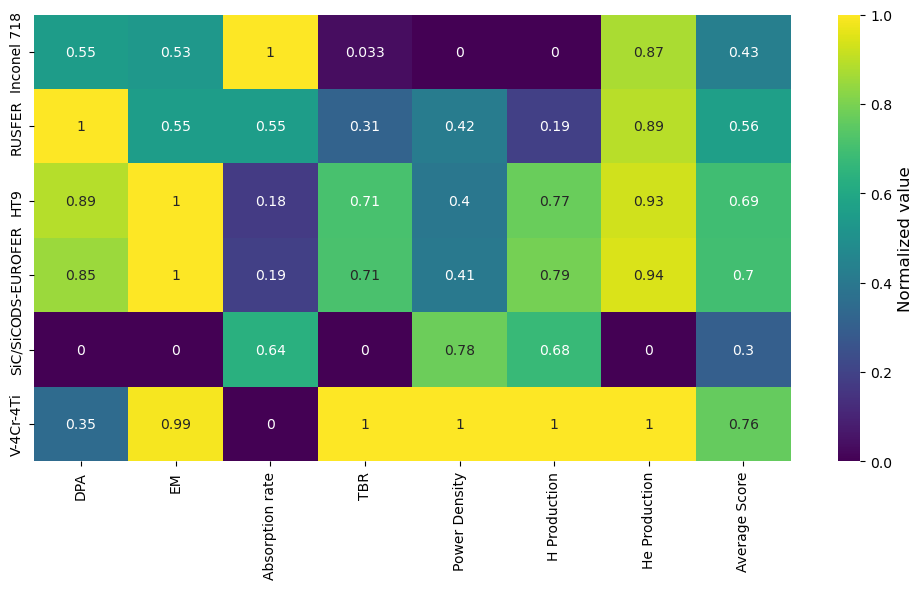

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# data = {
#     '': ["Inconel 718", "SS316L", "SiC/SiC", "ODS-EUROFER", "V-4Cr-4Ti", "HT9"],
#     'DPA': [inconel718_dpa['DPA'].item(), ss316l_dpa['DPA'].item(), silicon_carbide_dpa['DPA'].item(), vcrti_dpa['DPA'].item(), ods_eurofer_dpa['DPA'].item(), ht9_dpa['DPA'].item()],
#     'EM': [inconel718_em, ss316l_em, silicon_carbide_em, vcrti_em, ods_eurofer_em, ht9_em],
#     'Absorption rate': [inconel718_abs['mean'].item(), ss316l_abs['mean'].item(), silicon_carbide_abs['mean'].item(), vcrti_abs['mean'].item(), ods_eurofer_abs['mean'].item(), ht9_abs['mean'].item()],
#     'TBR': [inconel718_tbr['TBR'].item(), ss316l_tbr['TBR'].item(), silicon_carbide_tbr['TBR'].item(), vcrti_tbr['TBR'].item(), ods_eurofer_tbr['TBR'].item(), ht9_tbr['TBR'].item()],
#     'Power Density': [inconel718_pd, ss316l_pd, silicon_carbide_pd, vcrti_pd, ods_eurofer_pd, ht9_pd],
# }

data = {
    '': ["Inconel 718", "RUSFER", "HT9", "ODS-EUROFER", "SiC/SiC", "V-4Cr-4Ti"],
    'DPA': [
        inconel718_dpa['DPA'].item(), 
        rusfer_dpa['DPA'].item(), 
        ht9_dpa['DPA'].item(), 
        ods_eurofer_dpa['DPA'].item(), 
        silicon_carbide_dpa['DPA'].item(), 
        vcrti_dpa['DPA'].item()
    ],
    'EM': [
        inconel718_em, 
        rusfer_em, 
        ht9_em, 
        ods_eurofer_em, 
        silicon_carbide_em, 
        vcrti_em
    ],
    'Absorption rate': [
        inconel718_abs['mean'].item(), 
        rusfer_abs['mean'].item(), 
        ht9_abs['mean'].item(), 
        ods_eurofer_abs['mean'].item(), 
        silicon_carbide_abs['mean'].item(), 
        vcrti_abs['mean'].item()
    ],
    'TBR': [
        inconel718_tbr['TBR'].item(), 
        rusfer_tbr['TBR'].item(), 
        ht9_tbr['TBR'].item(), 
        ods_eurofer_tbr['TBR'].item(), 
        silicon_carbide_tbr['TBR'].item(), 
        vcrti_tbr['TBR'].item()
    ],
    'Power Density': [
        inconel718_pd, 
        rusfer_pd, 
        ht9_pd, 
        ods_eurofer_pd, 
        silicon_carbide_pd, 
        vcrti_pd
    ],
    'H Production': [
        h_inconel718, 
        h_rusfer, 
        h_ht9, 
        h_ods_eurofer, 
        h_silicon_carbide, 
        h_vcrti
    ],
    'He Production': [
        he_inconel718, 
        he_rusfer, 
        he_ht9, 
        he_ods_eurofer, 
        he_silicon_carbide, 
        he_vcrti
    ]
}

df = pd.DataFrame(data).set_index('')

# Normalize values for visual comparison
df_norm = df.copy()

for col in df.columns:
    if col == 'DPA':
        # Invert normalization: lower is better
        df_norm[col] = (df[col].max() - df[col]) / (df[col].max() - df[col].min())
    elif col == 'Power Density':
        # Invert normalization: lower is better
        df_norm[col] = (df[col].max() - df[col]) / (df[col].max() - df[col].min())
    elif col == 'H Production':
        # Invert normalization: lower is better
        df_norm[col] = (df[col].max() - df[col]) / (df[col].max() - df[col].min())
    elif col == 'He Production':
        # Invert normalization: lower is better
        df_norm[col] = (df[col].max() - df[col]) / (df[col].max() - df[col].min())
    else:
        # Standard min-max normalization
        df_norm[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
        
# Calculate average score per material
df_norm['Average Score'] = df_norm.mean(axis=1)

# Identify the best-performing material
best_material = df_norm['Average Score'].idxmax()
best_score = df_norm['Average Score'].max()

print(f"\nBest-performing material overall: {best_material} (average normalized score = {best_score:.2f})")

# Drop average column for heatmap
df_norm_plot = df_norm.drop(columns='Average Score')

# Plot the heatmap
plt.figure(figsize=(10, 6))

ax = sns.heatmap(df_norm, annot=True, cmap="viridis", cbar_kws={'label': 'Normalized value'})
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=10)
cbar.ax.yaxis.label.set_size(12) 
# plt.title("Normalized comparison of materials across key metrics")
plt.tight_layout()
plt.savefig('norm_comparison.pdf', format='pdf', bbox_inches='tight')

plt.show()

/tmp/ipykernel_1687/1782947644.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  viridis = plt.cm.get_cmap("RdYlGn", 4)


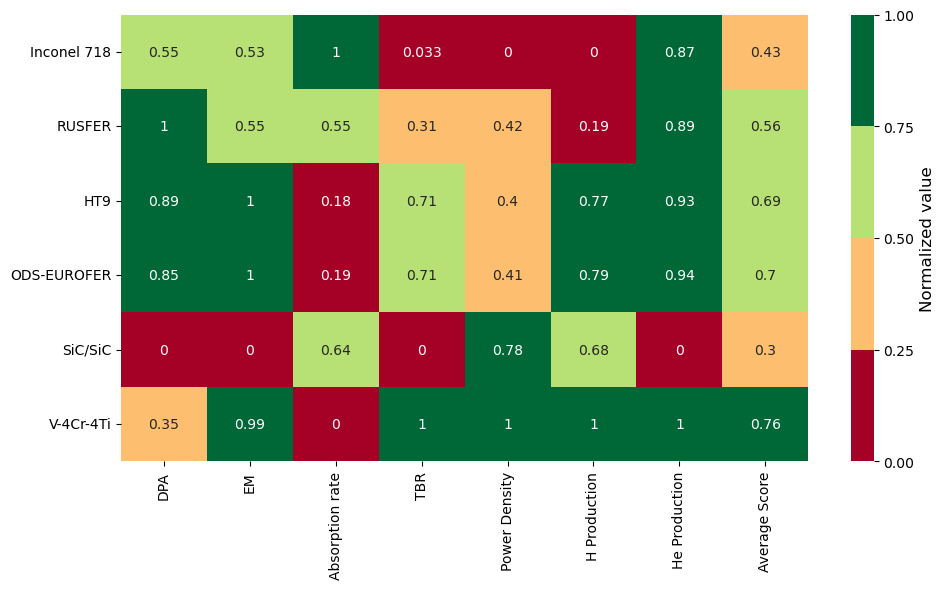

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
import numpy as np

# Crea una versione discreta della colormap RdYlGn con 4 colori
viridis = plt.cm.get_cmap("RdYlGn", 4)
cmap = mcolors.ListedColormap(viridis(np.linspace(0, 1, 4)))

# Definisci i confini per la discretizzazione
bounds = [0.0, 0.25, 0.5, 0.75, 1.0]
norm = mcolors.BoundaryNorm(bounds, ncolors=4)

# Plot della heatmap
plt.figure(figsize=(10, 6))
ax = sns.heatmap(df_norm, annot=True, cmap=cmap, norm=norm, cbar_kws={'label': 'Normalized value'})

# Ruota le etichette sull'asse y (orizzontali)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

# Migliora leggibilità della colorbar
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=10)
cbar.ax.yaxis.label.set_size(12)

plt.tight_layout()
plt.savefig('norm_comparison.pdf', format='pdf', bbox_inches='tight')
plt.show()


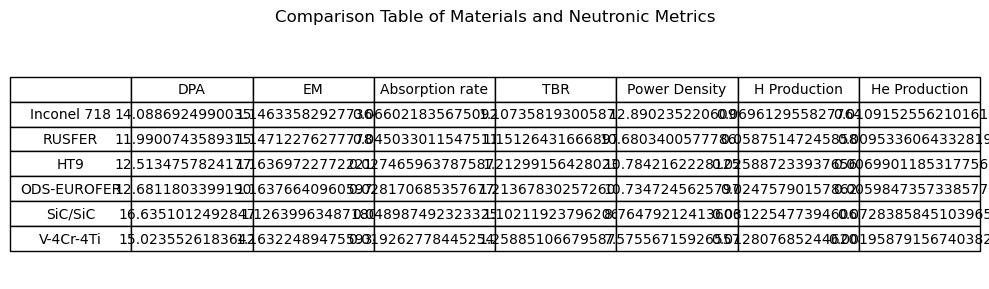

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(data)

fig, ax = plt.subplots(figsize=(10, 3)) 
ax.axis('off')  

table = ax.table(cellText=df.values, colLabels=df.columns, cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)  

plt.title("Comparison Table of Materials and Neutronic Metrics", pad=20)
plt.tight_layout()
plt.show()


## D1S - Shut Down Dose Rate

In [21]:
seconds_per_day = 60 * 60 * 24
seconds_per_year = 60 * 60 * 24 * 365.25
seconds_per_50_years = seconds_per_year * 50
seconds_per_200_years = seconds_per_year * 200
background = 1/seconds_per_year

In [22]:
df_inconel718 = pd.read_csv(f"d1s_results/inconel718_dose_rate_vs_time.csv")
df_inconel718['Max_Dose_Rate_mSv_per_s'] = df_inconel718['Max_Dose_Rate_mSv_per_s'].apply(lambda x: eval(x)[0])
df_ss316l = pd.read_csv(f"d1s_results/ss316l_dose_rate_vs_time.csv")
df_ss316l['Max_Dose_Rate_mSv_per_s'] = df_ss316l['Max_Dose_Rate_mSv_per_s'].apply(lambda x: eval(x)[0])
df_siliconcarbide = pd.read_csv(f"d1s_results/silicon_carbide_dose_rate_vs_time.csv")
df_siliconcarbide['Max_Dose_Rate_mSv_per_s'] = df_siliconcarbide['Max_Dose_Rate_mSv_per_s'].apply(lambda x: eval(x)[0])
df_ods_eurofer = pd.read_csv(f"d1s_results/ods_eurofer_dose_rate_vs_time.csv")
df_ods_eurofer['Max_Dose_Rate_mSv_per_s'] = df_ods_eurofer['Max_Dose_Rate_mSv_per_s'].apply(lambda x: eval(x)[0])
df_ht9 = pd.read_csv(f"d1s_results/ht9_dose_rate_vs_time.csv")
df_ht9['Max_Dose_Rate_mSv_per_s'] = df_ht9['Max_Dose_Rate_mSv_per_s'].apply(lambda x: eval(x)[0])
df_vcrti = pd.read_csv(f"d1s_results/vcrti_dose_rate_vs_time.csv")
df_vcrti['Max_Dose_Rate_mSv_per_s'] = df_vcrti['Max_Dose_Rate_mSv_per_s'].apply(lambda x: eval(x)[0])
df_rusfer = pd.read_csv(f"d1s_results/rusfer_dose_rate_vs_time.csv")
df_rusfer['Max_Dose_Rate_mSv_per_s'] = df_rusfer['Max_Dose_Rate_mSv_per_s'].apply(lambda x: eval(x)[0])

# plt.loglog(df_inconel718['Time_s'], df_inconel718['Max_Dose_Rate_mSv_per_s'], label='Inconel 718')
# plt.loglog(df_ss316l['Time_s'], df_ss316l['Max_Dose_Rate_mSv_per_s'], label='SS316L')
# plt.loglog(df_siliconcarbide['Time_s'], df_siliconcarbide['Max_Dose_Rate_mSv_per_s'], label='SiC/SiC')
# plt.loglog(df_ods_eurofer['Time_s'], df_ods_eurofer['Max_Dose_Rate_mSv_per_s'], label='ODS-EUROFER')
# plt.loglog(df_vcrti['Time_s'], df_vcrti['Max_Dose_Rate_mSv_per_s'], label='V-4Cr-4Ti')
# plt.loglog(df_ht9['Time_s'], df_ht9['Max_Dose_Rate_mSv_per_s'], label='HT9')
# plt.xlabel("Time (s)")
# plt.ylabel("Max Dose Rate (mSv/s)")

# plt.axvline(seconds_per_day, color='orange', linestyle='--', label='1 day')
# plt.axvline(seconds_per_year, color='green', linestyle='--', label='1 year')
# plt.axvline(seconds_per_50_years, color='red', linestyle='--', label='50 years')
# plt.axvline(seconds_per_200_years, color='purple', linestyle='--', label='200 years')
# plt.axhline(background, color='black', linestyle='-')
# plt.text(
#     x=1e1,  
#     y=background * 1.5,  
#     s='Natural background',
#     color='black',
#     fontsize=10
# )

# plt.ylim(1e-9, 1e6)  # Set y-axis limits to focus on the range of interest
# plt.xlim(1e0, 1e12)  # Set x-axis limits to focus on the range of interest
# plt.legend()
# plt.grid()
# plt.tight_layout()
# plt.show()

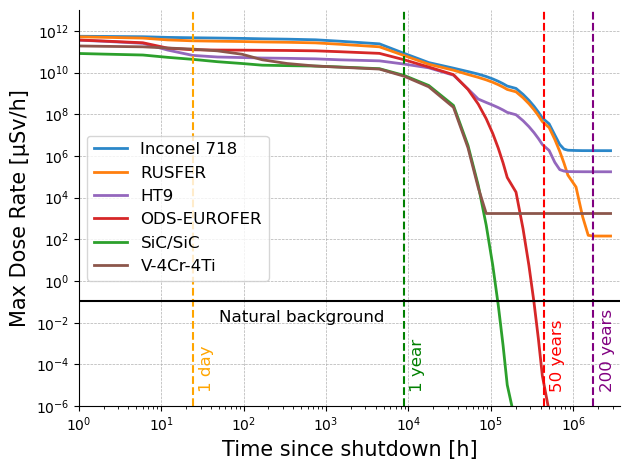

In [23]:
materials = {
    'Inconel 718': (df_inconel718, "#2b87c9"),
    'RUSFER': (df_rusfer, "#ff7f0e"),
    'HT9': (df_ht9, "#9467bd"),
    # 'SS316L': (df_ss316l, "#ff7f0e"),
    'ODS-EUROFER': (df_ods_eurofer, "#d62728"),
    'SiC/SiC': (df_siliconcarbide, "#2ca02c"),
    'V-4Cr-4Ti': (df_vcrti, "#8c564b"),

}

for label, (df, color) in materials.items():
    df_plot = df[df['Max_Dose_Rate_mSv_per_s'] > 0]
    plt.loglog(df_plot['Time_s'] / 3600, df_plot['Max_Dose_Rate_mSv_per_s'] * 3.6e6, label=label, color=color, linewidth=2)

def annotate_vline(x, label, color):
    plt.axvline(x, color=color, linestyle='--')
    plt.text(x * 1.2, 5e-6, label, color=color, rotation=90, va='bottom', fontsize=12)

annotate_vline(seconds_per_day / 3600, "1 day", "orange")
annotate_vline(seconds_per_year / 3600, "1 year", "green")
annotate_vline(seconds_per_50_years / 3600, "50 years", "red")
annotate_vline(seconds_per_200_years / 3600, "200 years", "purple")

plt.xlabel("Time since shutdown [h]", fontsize=15)
plt.ylabel("Max Dose Rate [µSv/h]", fontsize=15)
plt.legend(fontsize=12)
plt.grid(True, which='major', linestyle='--', linewidth=0.5)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.axhline(background * 3.6e6, color='black', linestyle='-')
plt.text(
    x=5e1,  
    y=background * 3.6e6 * 0.1,  
    s='Natural background',
    color='black',
    fontsize=12
)


plt.ylim(1e-6, 1e13)  # Set y-axis limits to focus on the range of interest
plt.xlim(1e0, 420*seconds_per_year/3600)  # Set x-axis limits to focus on the range of interest
plt.tight_layout()
plt.savefig('dose_rate_vs_time.pdf', format='pdf', bbox_inches='tight')
plt.show()
